In [13]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# --- Step 1: Load image ---
# Replace with your own image path
image_path = '/content/ATRB9069.jpg'
img = cv2.imread(image_path)

# Convert from BGR to RGB (for Matplotlib)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Resize for faster computation
img = cv2.resize(img, (128, 128))

# --- Step 2: Normalize pixel values ---
img_normalized = img / 255.0

# --- Step 3: Apply PCA on each color channel separately ---
def apply_pca_channel(channel, n_components=50):
    # Flatten rows as samples, columns as features
    pca = PCA(n_components=n_components)
    transformed = pca.fit_transform(channel)
    reconstructed = pca.inverse_transform(transformed)
    return reconstructed, pca.explained_variance_ratio_.sum()

# Apply PCA to each channel
channels = cv2.split(img_normalized)
reconstructed_channels = []
explained_variances = []

for ch in channels:
    rec, var = apply_pca_channel(ch, n_components=50)
    reconstructed_channels.append(rec)
    explained_variances.append(var)

# Merge reconstructed channels
reconstructed_img = cv2.merge(reconstructed_channels)

# --- Step 4: Display results ---
plt.figure(figsize=(12,6))

plt.subplot(1,2,1)
plt.imshow(img_normalized)
plt.title('Original Image')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(np.clip(reconstructed_img, 0, 1))
plt.title(f'PCA Reconstructed Image\n(50 Components, {np.mean(explained_variances)*100:.2f}% Variance)')
plt.axis('off')

plt.show()


KeyboardInterrupt: 

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 214ms/step


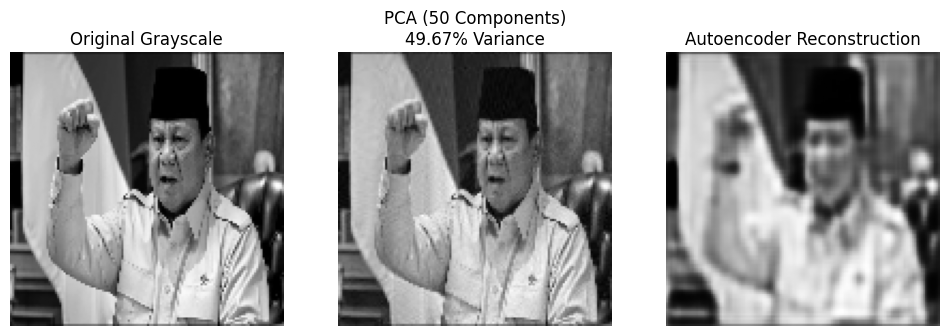

In [9]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from tensorflow.keras import layers, models

# --- Step 1: Load and preprocess image ---
image_path = '/content/2.jpg'  # change this
img = cv2.imread(image_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
img = cv2.resize(img, (128, 128))
img = img.astype('float32') / 255.0  # normalize

# For PCA, we use grayscale (simpler for comparison)
gray = cv2.cvtColor((img * 255).astype('uint8'), cv2.COLOR_RGB2GRAY)
gray = gray / 255.0

# --- Step 2: PCA reconstruction ---
def apply_pca(image, n_components=50):
    pca = PCA(n_components=n_components)
    transformed = pca.fit_transform(image)
    reconstructed = pca.inverse_transform(transformed)
    return reconstructed, pca.explained_variance_ratio_.sum()

pca_reconstructed, pca_var = apply_pca(gray, n_components=50)

# --- Step 3: Autoencoder model ---
input_img = layers.Input(shape=(128, 128, 1))

# Encoder
x = layers.Conv2D(32, (3, 3), activation='relu', padding='same')(input_img)
x = layers.MaxPooling2D((2, 2), padding='same')(x)
x = layers.Conv2D(16, (3, 3), activation='relu', padding='same')(x)
encoded = layers.MaxPooling2D((2, 2), padding='same')(x)

# Decoder
x = layers.Conv2D(16, (3, 3), activation='relu', padding='same')(encoded)
x = layers.UpSampling2D((2, 2))(x)
x = layers.Conv2D(32, (3, 3), activation='relu', padding='same')(x)
x = layers.UpSampling2D((2, 2))(x)
decoded = layers.Conv2D(1, (3, 3), activation='sigmoid', padding='same')(x)

autoencoder = models.Model(input_img, decoded)
autoencoder.compile(optimizer='adam', loss='mse')

# --- Step 4: Prepare data for training (single image) ---
# We can "simulate" a dataset by repeating the same image
gray_expanded = np.expand_dims(gray, axis=(0, -1))
data = np.repeat(gray_expanded, 50, axis=0)  # repeat for training stability

# --- Step 5: Train autoencoder ---
autoencoder.fit(data, data, epochs=50, batch_size=10, verbose=0)

# --- Step 6: Reconstruction ---
autoencoded_img = autoencoder.predict(np.expand_dims(gray, axis=(0, -1)))[0, :, :, 0]

# --- Step 7: Display results ---
plt.figure(figsize=(12,6))

plt.subplot(1,3,1)
plt.imshow(gray, cmap='gray')
plt.title("Original Grayscale")
plt.axis('off')

plt.subplot(1,3,2)
plt.imshow(pca_reconstructed, cmap='gray')
plt.title(f"PCA (50 Components)\n{pca_var*50:.2f}% Variance")
plt.axis('off')

plt.subplot(1,3,3)
plt.imshow(autoencoded_img, cmap='gray')
plt.title("Autoencoder Reconstruction")
plt.axis('off')

plt.show()
